# SVAR: enfermedad holandesa y fricciones ante el shock de IED de Stargate Argentina

Este notebook complementa al MEGC walrasiano (`stargate_cge.ipynb`), pero es independiente: no lo importa y descarga sus propios datos.

**Pregunta.** El MEGC es estático y walrasiano: los mercados se vacían al instante, los precios son flexibles y el bien transable tiene precio mundial fijo. Por construcción no puede mostrar (i) la apreciación del tipo de cambio real que caracteriza a la enfermedad holandesa, (ii) la velocidad del ajuste ni (iii) las rigideces que lo demoran. Acá se rompe ese supuesto y se deja que los datos argentinos 2006–2026 determinen la dinámica, con un **VAR estructural (SVAR)** trimestral.

**Estrategia.**
1. Estimar cómo responde la economía a un shock de inversión extranjera directa (IED), que es el canal por el que entra el CapEx de Stargate.
2. **Aislar la enfermedad holandesa**: separar la parte de la respuesta del producto transable que pasa por el tipo de cambio real (efecto gasto de Corden y Neary, 1982) del resto de los canales, con un contrafáctico que apaga el canal cambiario (Bernanke, Gertler y Watson, 1997).
3. Medir las **fricciones**: cuánto tarda el ajuste, comparado con el ajuste instantáneo del MEGC.
4. Escalar las respuestas al tamaño de Stargate (USD 18.900 M) y compararlas con el MEGC.

## 1. Qué supuestos del MEGC se rompen

| Supuesto del MEGC walrasiano | Cómo lo trata el SVAR |
|---|---|
| Vaciado instantáneo de mercados | Ajuste gradual: las variables responden con rezagos estimados de los datos |
| Bien transable con precio mundial fijo, sin tipo de cambio real | El tipo de cambio real multilateral (ITCRM) es endógeno |
| Estática comparativa (corto y largo plazo como dos fotos) | Trayectoria completa trimestre a trimestre, con bandas de confianza |
| Rigideces ausentes | Rigideces implícitas en la persistencia de las respuestas |
| Shock = operación del datacenter (demanda eléctrica) | Shock = entrada de IED (fase de inversión y financiamiento) |

La última fila importa: los dos modelos miran **fases distintas** del proyecto. El MEGC simula la operación (4,55 TWh/año); el SVAR, la entrada de capitales que la financia, que es donde la teoría ubica el efecto gasto de la enfermedad holandesa. Son complementarios.

In [1]:
import io
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", message=".*p-value.*")  # avisos de interpolación de KPSS
warnings.filterwarnings("ignore", category=FutureWarning)  # avisos de cambios futuros de API (statsmodels, pandas)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Parámetros del análisis
H = 20                  # horizonte de las respuestas, en trimestres (5 años)
N_BOOT = 500            # réplicas bootstrap de la especificación base
N_BOOT_ROB = 200        # réplicas bootstrap de cada prueba de robustez
NIVEL = 90              # nivel de las bandas de confianza (%)
CAPEX = 18.9            # USD bn, mismo dato que el MEGC
TRIM_DESEMBOLSO = 12    # supuesto: desembolso uniforme en 3 años
SEMILLA = 42

In [2]:
# Estilo de los gráficos: paleta de referencia, una serie por panel, grilla y ejes recesivos
AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, GRILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "axes.titlelocation": "left",
    "font.size": 9, "lines.linewidth": 2, "legend.frameon": False,
})

## 2. Datos

Todas las series son públicas y oficiales. Se descargan en cada ejecución y se guardan en `datos_var/` como respaldo por si alguna fuente no responde.

| Variable | Serie | Fuente | Transformación |
|---|---|---|---|
| IED | Cuenta financiera, inversión directa, pasivos: participaciones de capital + instrumentos de deuda (USD M, trimestral) | INDEC, balance de pagos, vía [API Series de Tiempo](https://datosgobar.github.io/series-tiempo-ar-api/) | Flujo en USD bn por trimestre |
| Energía | EMAE, electricidad, gas y agua | INDEC, vía API Series de Tiempo | 100 × Δ log |
| Transable / no transable | EMAE industria manufacturera ÷ promedio geométrico de construcción y comercio | INDEC, vía API Series de Tiempo | 100 × Δ log del cociente |
| Tipo de cambio real | ITCRM, promedio mensual (base 17-12-15 = 100; sube = depreciación) | [BCRA](https://www.bcra.gob.ar/PublicacionesEstadisticas/Indices_tipo_cambio_multilateral.asp) | Promedio trimestral, 100 × Δ log |
| Términos del intercambio (control exógeno) | Índice de términos del intercambio | INDEC, vía API Series de Tiempo | 100 × Δ log, contemporáneo y 1 rezago |

La industria manufacturera es el sector transable "rezagado" de Corden y Neary (1982); construcción y comercio son no transables típicos. Si hay enfermedad holandesa, el cociente transable / no transable cae y el ITCRM se aprecia (baja).

In [3]:
API = "https://apis.datos.gob.ar/series/api/series/"
ITCRM_XLSX = "https://www.bcra.gob.ar/Pdfs/PublicacionesEstadisticas/ITCRMSerie.xlsx"
CACHE = Path("datos_var")
CACHE.mkdir(exist_ok=True)

SERIES_EMAE = {"industria": "11.3_VMASD_2004_M_23", "construccion": "11.3_VMATC_2004_M_12",
               "comercio": "11.3_AGCS_2004_M_41", "energia": "11.3_ITC_2004_M_21"}
SERIES_TRIM = {"ied_capital": "160.2_CFIN_PASINTAL_0_T_57", "ied_deuda": "160.2_CFIN_INUDA_0_T_52",
               "tot": "82.2_ITI_2004_T_27"}


def descargar(url: str) -> bytes:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})  # la API rechaza pedidos sin User-Agent
    with urllib.request.urlopen(req, timeout=90) as r:
        return r.read()


def serie_api(ids: dict, collapse: str | None = None) -> pd.DataFrame:
    url = f"{API}?ids={','.join(ids.values())}&format=csv&limit=1000&start_date=2004-01-01"
    if collapse:
        url += f"&collapse={collapse}&collapse_aggregation=avg"
    df = pd.read_csv(io.BytesIO(descargar(url)), parse_dates=[0], index_col=0)
    df.columns = list(ids)
    return df


def itcrm_bcra() -> pd.DataFrame:
    hoja = pd.read_excel(io.BytesIO(descargar(ITCRM_XLSX)), sheet_name="ITCRM y bilaterales prom. mens.",
                         header=None).iloc[:, :2]
    hoja.columns = ["fecha", "itcrm"]
    hoja["fecha"] = pd.to_datetime(hoja["fecha"], errors="coerce", format="mixed")
    s = hoja.dropna().set_index("fecha")["itcrm"].astype(float)
    q = s.resample("QS").agg(["mean", "count"])
    return q.loc[q["count"] == 3, ["mean"]].rename(columns={"mean": "itcrm"})  # solo trimestres completos


def cargar(nombre: str, funcion) -> pd.DataFrame:
    archivo = CACHE / f"{nombre}.csv"
    try:
        df = funcion()
        df.to_csv(archivo)
        origen = "descarga"
    except Exception as e:
        if not archivo.exists():
            raise
        df = pd.read_csv(archivo, index_col=0, parse_dates=True)
        origen = f"caché local ({type(e).__name__})"
    print(f"{nombre:6s} {origen}: {df.index.min():%Y-%m} a {df.index.max():%Y-%m}")
    return df


datos = pd.concat([cargar("emae", lambda: serie_api(SERIES_EMAE, "quarter")),
                   cargar("trim", lambda: serie_api(SERIES_TRIM)),
                   cargar("itcrm", itcrm_bcra)], axis=1, sort=True).dropna()
datos.index = pd.PeriodIndex(datos.index, freq="Q")
print(f"\nMuestra común: {datos.index.min()} a {datos.index.max()} ({len(datos)} trimestres)")
datos.tail()

emae   descarga: 2004-01 a 2026-04


trim   descarga: 2004-01 a 2026-04


itcrm  descarga: 1997-01 a 2026-07

Muestra común: 2006Q1 a 2026Q1 (81 trimestres)


,industria,construccion,comercio,energia,ied_capital,ied_deuda,tot,itcrm
2025Q1,110.255,132.309,150.391,156.332,505.377,359.499,148.151,80.418
2025Q2,118.814,127.165,158.547,146.141,495.181,"2,181.368",138.165,84.123
2025Q3,123.814,135.830,153.594,151.062,"1,709.596","3,215.001",138.040,95.311
2025Q4,122.620,126.462,152.751,145.620,919.396,"-5,023.689",140.594,96.529
2026Q1,108.252,135.485,150.349,154.759,"2,673.779",160.342,148.097,89.954


In [4]:
ETIQUETAS = {"ied": "IED (USD bn por trimestre)", "energia": "Energía (EMAE EGA)",
             "relativo_tn": "Producto transable / no transable", "itcrm": "Tipo de cambio real (ITCRM)"}
UNIDADES = {"ied": "USD bn", "energia": "%", "relativo_tn": "%", "itcrm": "% (+ = depreciación)"}
ORDEN_BASE = ["ied", "energia", "relativo_tn", "itcrm"]


def armar(datos, orden=ORDEN_BASE, ied="total", control_tot=True, hasta=None):
    # Devuelve (Y, X): variables endógenas en el orden de Cholesky y regresores exógenos
    v = pd.DataFrame(index=datos.index)
    v["ied"] = (datos["ied_capital"] + (datos["ied_deuda"] if ied == "total" else 0)) / 1000
    v["energia"] = 100 * np.log(datos["energia"]).diff()
    v["relativo_tn"] = 100 * (np.log(datos["industria"])
                              - 0.5 * (np.log(datos["construccion"]) + np.log(datos["comercio"]))).diff()
    v["itcrm"] = 100 * np.log(datos["itcrm"]).diff()

    q = v.index.quarter
    x = pd.DataFrame({"q2": q == 2, "q3": q == 3, "q4": q == 4,  # estacionalidad: el EMAE sectorial es serie original
                      "covid_2020q2": v.index == pd.Period("2020Q2"),
                      "covid_2020q3": v.index == pd.Period("2020Q3")}, index=v.index).astype(float)
    if control_tot:
        dtot = 100 * np.log(datos["tot"]).diff()
        x["tot"], x["tot_l1"] = dtot, dtot.shift(1)

    m = pd.concat([v, x], axis=1).dropna()
    if hasta:
        m = m.loc[:hasta]
    m.index = m.index.to_timestamp()
    x = m[x.columns]
    x = x.loc[:, x.abs().sum() > 0]  # descarta dummies vacías (p. ej., pandemia fuera de la muestra)
    return m[orden], x


Y, X = armar(datos)
print(f"Muestra de estimación: {Y.index[0]:%Y}T{Y.index[0].quarter} a {Y.index[-1]:%Y}T{Y.index[-1].quarter} "
      f"({len(Y)} trimestres)")
Y.describe().T

Muestra de estimación: 2006T3 a 2026T1 (79 trimestres)


,count,mean,std,min,25%,50%,75%,max
ied,79.000,2.432,1.807,-4.104,1.472,2.355,3.346,7.821
energia,79.000,0.419,4.728,-10.172,-2.985,0.179,3.981,11.588
relativo_tn,79.000,-0.294,8.090,-16.268,-8.440,1.502,5.337,22.405
itcrm,79.000,-0.776,6.767,-23.437,-4.401,-1.147,1.335,24.216


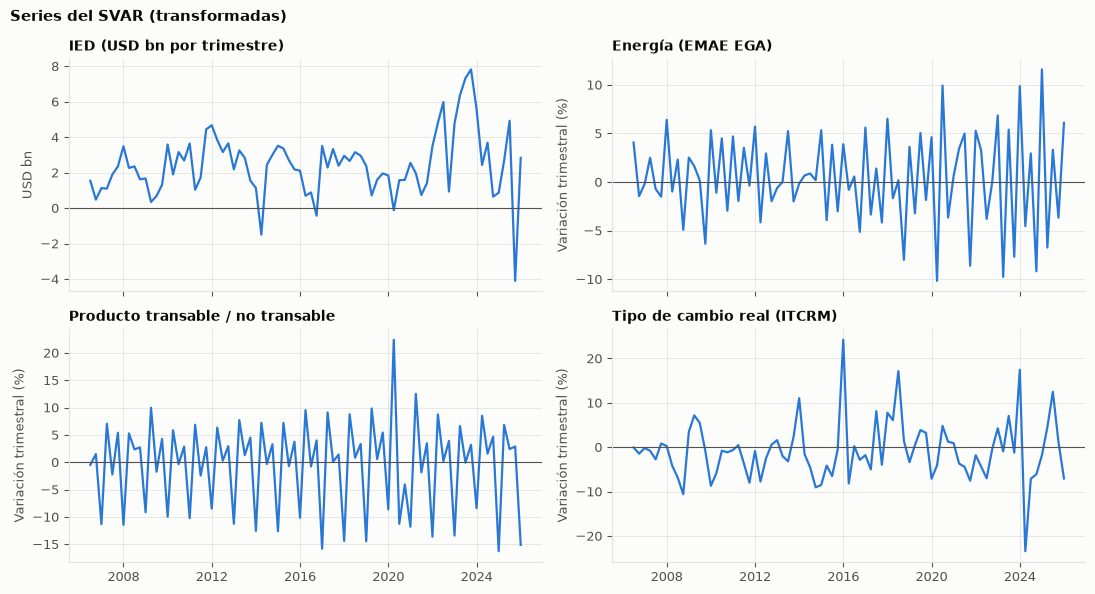

In [5]:
fig, ejes = plt.subplots(2, 2, figsize=(11, 6), sharex=True)
for ax, col in zip(ejes.flat, ORDEN_BASE):
    ax.plot(Y.index, Y[col], color=AZUL, lw=1.6)
    ax.axhline(0, color=TINTA2, lw=0.8)
    ax.set_title(ETIQUETAS[col])
    ax.set_ylabel("USD bn" if col == "ied" else "Variación trimestral (%)")
fig.suptitle("Series del SVAR (transformadas)", x=0.01, ha="left", fontweight="bold", color=TINTA)
fig.tight_layout()
plt.show()

## 3. Especificación

### 3.1 Estacionariedad
El VAR se estima con variables estacionarias. Se usan dos pruebas con hipótesis nulas opuestas: ADF (H0: raíz unitaria) y KPSS (H0: estacionariedad). Una variable es estacionaria si ADF rechaza y KPSS no rechaza.

In [6]:
filas = []
for col in Y:
    p_adf = adfuller(Y[col], autolag="AIC")[1]
    p_kpss = kpss(Y[col], regression="c", nlags="auto")[1]
    filas.append({"variable": ETIQUETAS[col], "ADF p-valor": p_adf, "KPSS p-valor": p_kpss,
                  "conclusión": "estacionaria" if (p_adf < 0.05 and p_kpss > 0.05) else "revisar"})
pd.DataFrame(filas).set_index("variable")

,ADF p-valor,KPSS p-valor,conclusión
variable,,,
IED (USD bn por trimestre),0.000,0.100,estacionaria
Energía (EMAE EGA),0.011,0.100,estacionaria
Producto transable / no transable,0.000,0.100,estacionaria
Tipo de cambio real (ITCRM),0.000,0.100,estacionaria


### 3.2 Modelo e identificación

Forma reducida, con $y_t = (\text{IED}_t,\ \Delta e_t,\ \Delta (T/N)_t,\ \Delta q_t)'$ y $x_t$ las variables exógenas (constante, dummies estacionales y de pandemia, términos del intercambio):

$$y_t = c + \sum_{i=1}^{p} A_i\, y_{t-i} + B\, x_t + u_t,\qquad u_t = P\,\varepsilon_t,\qquad PP' = \Sigma_u$$

**Identificación recursiva (Cholesky)** con el orden IED → energía → transable/no transable → ITCRM:
- La IED va primero porque las decisiones de inversión directa se toman con anticipación y no reaccionan dentro del mismo trimestre a la actividad ni al tipo de cambio.
- El producto sectorial responde con rezago al tipo de cambio (contratos, planes de producción).
- El ITCRM, como precio de activo, reacciona en el trimestre a todo.

El shock de IED identificado no depende del orden de las otras tres variables. La robustez relevante es mover la IED de lugar (sección 7).

Los términos del intercambio entran como **exógenos**: en una economía pequeña los fija el mercado mundial, y controlarlos evita atribuir a la IED apreciaciones que en realidad vienen del precio de las commodities, el motor clásico de la enfermedad holandesa argentina.

In [7]:
seleccion = VAR(Y, exog=X).select_order(maxlags=4, trend="c")
print(seleccion.selected_orders)
P = max(1, int(seleccion.selected_orders["hqic"]))
print(f"\nRezagos elegidos: p = {P} (criterio de Hannan-Quinn, intermedio entre AIC y BIC)")
res = VAR(Y, exog=X).fit(P, trend="c")

{'aic': np.int64(4), 'bic': np.int64(0), 'hqic': np.int64(1), 'fpe': np.int64(3)}

Rezagos elegidos: p = 1 (criterio de Hannan-Quinn, intermedio entre AIC y BIC)


### 3.3 Diagnóstico
- **Estabilidad:** todas las raíces del polinomio característico deben quedar dentro del círculo unitario.
- **Autocorrelación residual:** prueba de Portmanteau (H0: residuos sin autocorrelación hasta 8 rezagos).
- **Normalidad:** Jarque-Bera multivariada. Su rechazo no invalida las estimaciones, pero justifica las bandas por bootstrap en lugar de las asintóticas.
- **Causalidad de Granger:** ¿la IED pasada ayuda a predecir cada variable?

In [8]:
blanco = res.test_whiteness(nlags=8)
normal = res.test_normality()
diag = pd.DataFrame({
    "valor": [f"{np.abs(res.roots).min():.3f}" if len(res.roots) else "-",
              "sí" if res.is_stable() else "no",
              f"{blanco.pvalue:.3f}", f"{normal.pvalue:.3f}"],
}, index=["Mínimo módulo de las raíces del polinomio característico (debe ser > 1)", "Modelo estable",
          "Portmanteau (8 rezagos), p-valor", "Jarque-Bera multivariada, p-valor"])
granger = pd.DataFrame({ETIQUETAS[c]: {"p-valor (F)": res.test_causality(c, "ied", kind="f").pvalue}
                        for c in Y.columns if c != "ied"}).T
display(diag)
print("Causalidad de Granger: IED → cada variable")
granger

,valor
Mínimo módulo de las raíces del polinomio característico (debe ser > 1),2.174
Modelo estable,sí
"Portmanteau (8 rezagos), p-valor",0.191
"Jarque-Bera multivariada, p-valor",0.000


Causalidad de Granger: IED → cada variable


,p-valor (F)
Energía (EMAE EGA),0.717
Producto transable / no transable,0.028
Tipo de cambio real (ITCRM),0.191


## 4. Respuestas a un shock de IED de USD 1.000 M

El shock se normaliza para que la IED suba USD 1 bn en el trimestre del impacto. Las variables en tasas de crecimiento se **acumulan**, de modo que cada curva muestra el desvío porcentual del **nivel** respecto de la trayectoria sin shock. Las bandas son del 90% y salen de un bootstrap de residuos (recursivo) con 500 réplicas.

In [9]:
def respuesta(Theta, E):
    # r_h = sum_{j<=h} Theta_{h-j} E_j : respuesta a una secuencia de shocks estructurales E (H+1 x k)
    return np.array([sum(Theta[h - j] @ E[j] for j in range(h + 1)) for h in range(len(E))])


def fijar(Theta, E, var, objetivo, shock):
    # Ajusta, período a período, el shock estructural `shock` para que la variable `var` siga `objetivo`
    E = E.copy()
    for h in range(len(E)):
        r = sum(Theta[h - j] @ E[j] for j in range(h + 1))
        E[h, shock] += (objetivo[h] - r[var]) / Theta[0, var, shock]
    return E


def analizar(r, H=H, perfil_ied=None):
    # Respuestas al shock de IED y contrafáctico sin canal cambiario, en niveles acumulados
    Th = r.irf(H).orth_irfs                    # (H+1, k, k): [horizonte, variable, shock]
    i_ied, i_q = r.names.index("ied"), r.names.index("itcrm")
    E = np.zeros((H + 1, r.neqs))
    if perfil_ied is None:
        E[0, i_ied] = 1 / Th[0, i_ied, i_ied]  # IED +USD 1 bn en el impacto
    else:
        E = fijar(Th, E, i_ied, perfil_ied, i_ied)  # la IED sigue exactamente el perfil del proyecto
    E_cf = fijar(Th, E, i_q, np.zeros(H + 1), i_q)  # shocks cambiarios que mantienen el ITCRM sin cambios

    def nivel(m):
        m = m.copy()
        crec = [j for j, n in enumerate(r.names) if n != "ied"]
        m[:, crec] = m[:, crec].cumsum(axis=0)
        return pd.DataFrame(m, columns=r.names)

    total, sin_canal = nivel(respuesta(Th, E)), nivel(respuesta(Th, E_cf))
    return {"total": total, "sin_canal_cambiario": sin_canal, "canal_cambiario": total - sin_canal}


def bootstrap(r, Y, X, n, funcion, semilla=SEMILLA):
    # Bootstrap de residuos recursivo: simula series con los coeficientes estimados y reestima el VAR
    rng = np.random.default_rng(semilla)
    u = r.resid.values - r.resid.values.mean(axis=0)
    A, C, p = r.coefs, r.coefs_exog, r.k_ar
    Xd = np.column_stack([np.ones(len(X)), X.values])
    Yv = Y.values
    salidas = []
    for _ in range(n):
        ys = Yv.copy()
        sorteo = u[rng.integers(0, len(u), len(u))]
        for t in range(p, len(Yv)):
            ys[t] = C @ Xd[t] + sum(A[i] @ ys[t - 1 - i] for i in range(p)) + sorteo[t - p]
        rb = VAR(pd.DataFrame(ys, index=Y.index, columns=Y.columns), exog=X).fit(p, trend="c")
        salidas.append(funcion(rb))
    return salidas


def bandas(salidas, clave, nivel=NIVEL):
    arr = np.array([s[clave].values for s in salidas])
    a = (100 - nivel) / 2
    return np.percentile(arr, a, axis=0), np.percentile(arr, 100 - a, axis=0)

In [10]:
def perfil_stargate(H=H):
    p = np.zeros(H + 1)
    p[:TRIM_DESEMBOLSO] = CAPEX / TRIM_DESEMBOLSO
    return p


def todo(r):
    return {"impulso": analizar(r), "stargate": analizar(r, perfil_ied=perfil_stargate())}


base = todo(res)
boot = bootstrap(res, Y, X, N_BOOT, todo)
print(f"Bootstrap completado: {len(boot)} réplicas")


def resumen(clave_escenario, componente="total", horizontes=(0, 4, 8, H)):
    est = base[clave_escenario][componente]
    lo, hi = bandas([b[clave_escenario] for b in boot], componente)
    filas = {}
    for col_i, col in enumerate(est.columns):
        filas[ETIQUETAS[col]] = {f"h={h}": f"{est.iloc[h, col_i]:+.3f} [{lo[h, col_i]:+.3f}; {hi[h, col_i]:+.3f}]"
                                 for h in horizontes}
    return pd.DataFrame(filas).T


print("Shock de IED de USD 1 bn: desvío del nivel (%; IED en USD bn) [banda del 90%]")
resumen("impulso")

Bootstrap completado: 500 réplicas
Shock de IED de USD 1 bn: desvío del nivel (%; IED en USD bn) [banda del 90%]


,h=0,h=4,h=8,h=20
IED (USD bn por trimestre),+1.000 [+1.000; +1.000],+0.002 [-0.036; +0.075],-0.000 [-0.002; +0.005],+0.000 [-0.000; +0.000]
Energía (EMAE EGA),+0.018 [-0.300; +0.468],-0.042 [-0.475; +0.457],-0.040 [-0.473; +0.466],-0.040 [-0.473; +0.466]
Producto transable / no transable,+0.020 [-0.215; +0.240],+0.558 [+0.087; +1.057],+0.561 [+0.093; +1.055],+0.561 [+0.092; +1.055]
Tipo de cambio real (ITCRM),-0.322 [-0.913; +0.271],+0.379 [-1.328; +2.150],+0.355 [-1.410; +2.164],+0.355 [-1.418; +2.168]


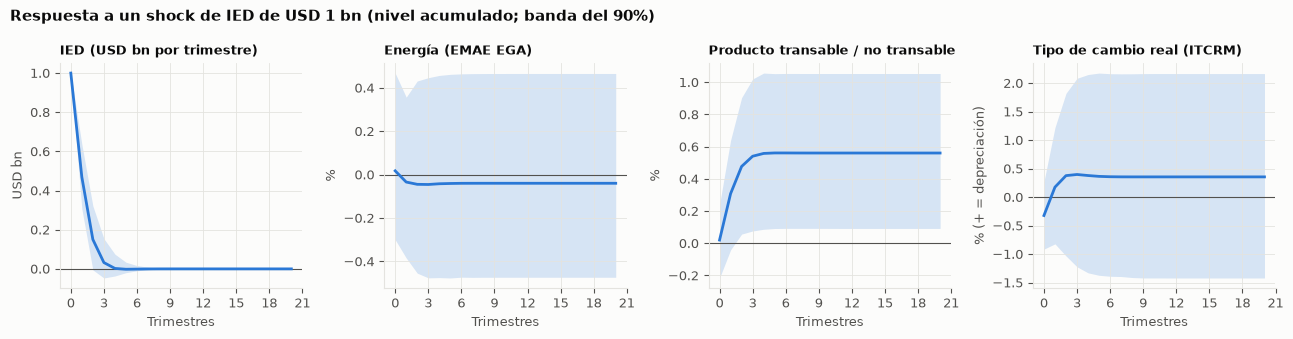

In [11]:
def graficar(escenario, titulo, componente="total"):
    est = base[escenario][componente]
    lo, hi = bandas([b[escenario] for b in boot], componente)
    h = np.arange(H + 1)
    fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4))
    for j, (ax, col) in enumerate(zip(ejes, est.columns)):
        ax.axhline(0, color=TINTA2, lw=0.8)
        ax.fill_between(h, lo[:, j], hi[:, j], color=AZUL, alpha=0.18, lw=0)
        ax.plot(h, est[col], color=AZUL)
        ax.set_title(ETIQUETAS[col], fontsize=9)
        ax.set_ylabel(UNIDADES[col])
        ax.set_xlabel("Trimestres")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", color=TINTA)
    fig.tight_layout()
    plt.show()


graficar("impulso", "Respuesta a un shock de IED de USD 1 bn (nivel acumulado; banda del 90%)")

## 5. Aislar la enfermedad holandesa

La enfermedad holandesa opera por dos vías (Corden y Neary, 1982):
- **Efecto gasto:** el ingreso de divisas eleva la demanda de no transables, aprecia el tipo de cambio real y contrae el sector transable rezagado.
- **Efecto movimiento de recursos:** el sector en auge, en este caso el datacenter y la energía que demanda, atrae trabajo y capital del resto.

Para aislar el efecto gasto se construye un **contrafáctico sin canal cambiario** (Bernanke, Gertler y Watson, 1997): en cada trimestre se agrega el shock cambiario exacto que deja el ITCRM en su trayectoria sin shock. Así:

$$\underbrace{r^{T/N}_h}_{\text{total}} \;=\; \underbrace{r^{T/N}_h\big|_{\Delta q = 0}}_{\text{otros canales}} \;+\; \underbrace{\left(r^{T/N}_h - r^{T/N}_h\big|_{\Delta q = 0}\right)}_{\text{canal cambiario (enfermedad holandesa)}}$$

"Otros canales" reúne todo lo que no pasa por el tipo de cambio: movimiento de recursos, demanda directa, encadenamientos y fricciones. Si la enfermedad holandesa operara, el componente cambiario sería **negativo** sobre el producto transable relativo.

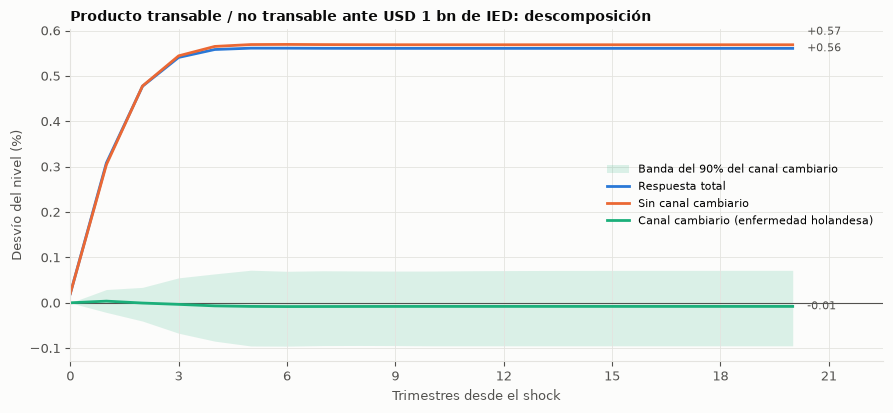

Canal cambiario aislado (desvío del nivel, %) [banda del 90%]


,h=0,h=4,h=8,h=20
IED (USD bn por trimestre),+0.000 [+0.000; +0.000],-0.004 [-0.039; +0.014],+0.000 [-0.003; +0.002],+0.000 [-0.000; +0.000]
Energía (EMAE EGA),+0.000 [+0.000; +0.000],-0.017 [-0.140; +0.059],-0.015 [-0.133; +0.067],-0.015 [-0.134; +0.067]
Producto transable / no transable,+0.000 [+0.000; +0.000],-0.007 [-0.085; +0.064],-0.008 [-0.094; +0.070],-0.008 [-0.095; +0.071]
Tipo de cambio real (ITCRM),-0.322 [-0.913; +0.271],+0.379 [-1.328; +2.150],+0.355 [-1.410; +2.164],+0.355 [-1.418; +2.168]


In [12]:
def grafico_descomposicion(escenario, titulo):
    h = np.arange(H + 1)
    series = [("total", "Respuesta total", AZUL), ("sin_canal_cambiario", "Sin canal cambiario", NARANJA),
              ("canal_cambiario", "Canal cambiario (enfermedad holandesa)", AQUA)]
    fig, ax = plt.subplots(figsize=(9, 4.2))
    ax.axhline(0, color=TINTA2, lw=0.8)
    lo, hi = bandas([b[escenario] for b in boot], "canal_cambiario")
    j = list(base[escenario]["total"].columns).index("relativo_tn")
    ax.fill_between(h, lo[:, j], hi[:, j], color=AQUA, alpha=0.15, lw=0, label="Banda del 90% del canal cambiario")
    finales = []
    for clave, nombre, color in series:
        y = base[escenario][clave]["relativo_tn"]
        ax.plot(h, y, color=color, label=nombre)
        finales.append(y.iloc[-1])
    # Etiquetas directas al final de cada curva, separadas si quedan muy juntas
    rango = np.ptp(ax.get_ylim())
    pos = sorted(range(len(finales)), key=lambda i: finales[i])
    ys = [finales[i] for i in pos]
    for n in range(1, len(ys)):
        ys[n] = max(ys[n], ys[n - 1] + 0.05 * rango)
    for i, y_etq in zip(pos, ys):
        ax.annotate(f"{finales[i]:+.2f}", (h[-1], finales[i]), xytext=(h[-1] + 0.4, y_etq), textcoords="data",
                    va="center", color=TINTA2, fontsize=8)
    ax.set_title(titulo)
    ax.set_xlabel("Trimestres desde el shock")
    ax.set_ylabel("Desvío del nivel (%)")
    ax.set_xlim(0, H + 2.5)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(loc="center right", fontsize=8)
    fig.tight_layout()
    plt.show()


grafico_descomposicion("impulso", "Producto transable / no transable ante USD 1 bn de IED: descomposición")
print("Canal cambiario aislado (desvío del nivel, %) [banda del 90%]")
resumen("impulso", "canal_cambiario")

## 6. Fricciones y rigideces: velocidad del ajuste

El MEGC supone que el ajuste es instantáneo: el 100% del efecto de largo plazo ocurre en el período del shock. En el SVAR la velocidad del ajuste es una estimación. Para cada variable se mide:
- **Ajuste en el impacto:** respuesta en h = 0 como % de la respuesta de largo plazo (h = 20).
- **Ajuste al año:** lo mismo en h = 4.
- **Vida media:** primer trimestre en que la respuesta alcanza el 50% de su valor de largo plazo.

Si se ajusta lento, hay rigideces (contratos, salarios nominales, costos de ajuste del capital, regulaciones) que el modelo walrasiano no tiene. Estas métricas solo se interpretan cuando la respuesta de largo plazo es significativamente distinta de cero.

In [13]:
def metricas_ajuste(escenario="impulso"):
    est = base[escenario]["total"]
    lo, hi = bandas([b[escenario] for b in boot], "total")
    filas = {}
    for j, col in enumerate(est.columns):
        if col == "ied":
            continue
        y, lp = est[col].values, est[col].values[-1]
        alcanzado = np.where(y / lp >= 0.5)[0] if lp != 0 else []
        filas[ETIQUETAS[col]] = {
            "Largo plazo (h=20)": lp,
            "Significativo al 90%": "sí" if (lo[-1, j] > 0 or hi[-1, j] < 0) else "no",
            "Ajuste en el impacto (%)": 100 * y[0] / lp,
            "Ajuste al año (%)": 100 * y[4] / lp,
            "Vida media (trimestres)": int(alcanzado[0]) if len(alcanzado) else np.nan,
        }
    return pd.DataFrame(filas).T


metricas_ajuste()

,Largo plazo (h=20),Significativo al 90%,Ajuste en el impacto (%),Ajuste al año (%),Vida media (trimestres)
Energía (EMAE EGA),-0.040,no,-44.005,105.669,1
Producto transable / no transable,0.561,sí,3.581,99.555,1
Tipo de cambio real (ITCRM),0.355,no,-90.767,106.696,2


In [14]:
fevd = res.fevd(H).decomp  # [variable, horizonte, shock]
i_ied = res.names.index("ied")
pd.DataFrame({ETIQUETAS[n]: {f"h={h}": 100 * fevd[i, h - 1, i_ied] for h in (1, 4, 8, H)}
              for i, n in enumerate(res.names) if n != "ied"}).T.rename_axis(
    "% de la varianza del error de pronóstico explicado por shocks de IED")

,h=1,h=4,h=8,h=20
% de la varianza del error de pronóstico explicado por shocks de IED,,,,
Energía (EMAE EGA),0.011,0.085,0.085,0.085
Producto transable / no transable,0.028,7.159,7.174,7.174
Tipo de cambio real (ITCRM),0.607,2.024,2.026,2.026


## 7. Escenario Stargate: USD 18.900 M en 12 trimestres

Se impone que la IED adicional siga el perfil del proyecto, USD 1,575 bn por trimestre durante 3 años. Para eso se agrega, período a período, el shock de IED necesario. El VAR es lineal, así que la respuesta escala con el monto. El desembolso trimestral está dentro del rango histórico de la IED (media de USD 2,4 bn por trimestre con desvío de 1,8 bn), lo que acota el riesgo de extrapolar fuera de la muestra.

IED histórica por trimestre: media 2.43, desvío 1.81, máximo 7.82 USD bn | Stargate: 1.575 USD bn por trimestre


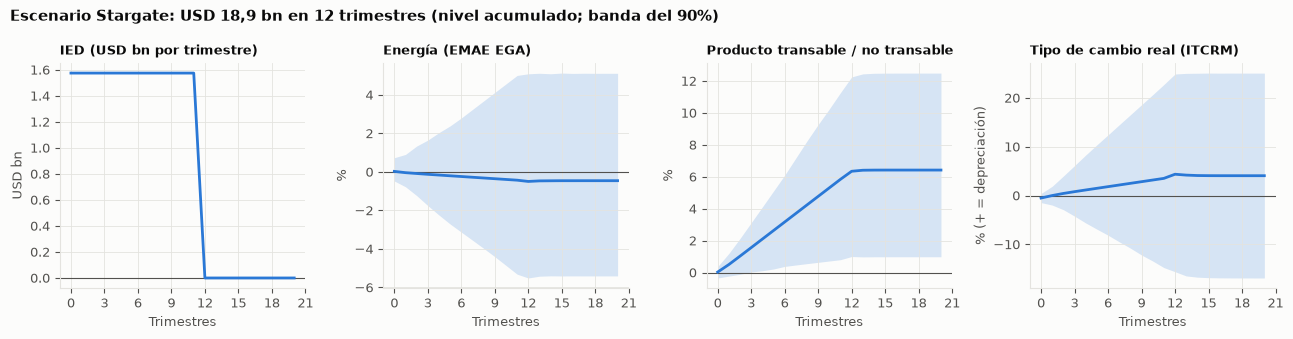

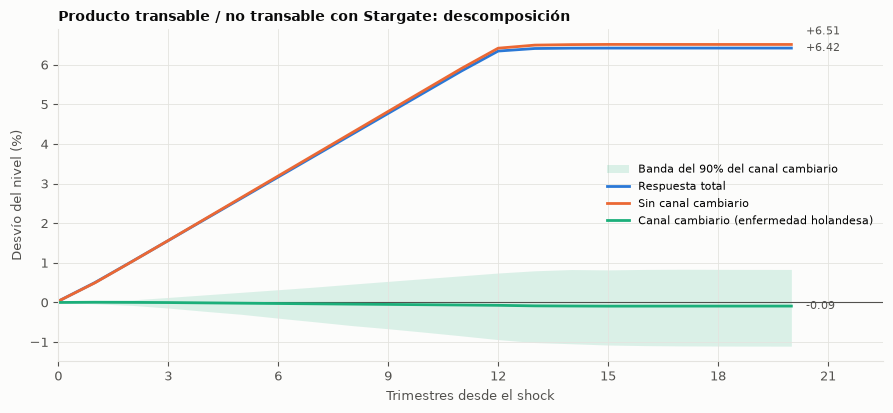

Escenario Stargate: desvío del nivel (%) [banda del 90%]


,h=4,h=8,h=12,h=20
IED (USD bn por trimestre),+1.575 [+1.575; +1.575],+1.575 [+1.575; +1.575],+0.000 [+0.000; +0.000],-0.000 [+0.000; +0.000]
Energía (EMAE EGA),-0.162 [-2.239; +2.039],-0.315 [-3.966; +3.683],-0.494 [-5.506; +5.094],-0.456 [-5.399; +5.119]
Producto transable / no transable,+2.096 [+0.115; +4.108],+4.236 [+0.558; +8.243],+6.345 [+1.005; +12.253],+6.420 [+0.990; +12.495]
Tipo de cambio real (ITCRM),+1.146 [-5.607; +8.301],+2.504 [-10.761; +16.543],+4.367 [-15.589; +24.892],+4.067 [-16.875; +25.076]


In [15]:
print(f"IED histórica por trimestre: media {Y['ied'].mean():.2f}, desvío {Y['ied'].std():.2f}, "
      f"máximo {Y['ied'].max():.2f} USD bn | Stargate: {CAPEX / TRIM_DESEMBOLSO:.3f} USD bn por trimestre")
graficar("stargate", "Escenario Stargate: USD 18,9 bn en 12 trimestres (nivel acumulado; banda del 90%)")
grafico_descomposicion("stargate", "Producto transable / no transable con Stargate: descomposición")
print("Escenario Stargate: desvío del nivel (%) [banda del 90%]")
resumen("stargate", horizontes=(4, 8, 12, H))

## 8. Robustez

Cada variante cambia un supuesto de la especificación base:
- **p = 2:** un rezago más.
- **IED solo capital:** excluye los préstamos entre empresas vinculadas; es más parecida a la inversión productiva nueva.
- **IED ordenada última:** la IED puede reaccionar en el mismo trimestre al tipo de cambio y a la actividad.
- **Sin términos del intercambio:** quita el control por precios de commodities.
- **Muestra 2006–2019:** excluye la pandemia y el período posterior.

In [16]:
variantes = {
    "Base": dict(),
    "p = 2": dict(p=2),
    "IED solo capital": dict(ied="capital"),
    "IED ordenada última": dict(orden=["energia", "relativo_tn", "itcrm", "ied"]),
    "Sin términos del intercambio": dict(control_tot=False),
    "Muestra 2006-2019": dict(hasta="2019Q4"),
}

filas = {}
for nombre, kw in variantes.items():
    p = kw.pop("p", P)
    Yv, Xv = armar(datos, **kw)
    rv = VAR(Yv, exog=Xv).fit(p, trend="c")
    est = analizar(rv)
    bs = bootstrap(rv, Yv, Xv, N_BOOT_ROB, analizar)
    fila = {}
    for comp, col, etiqueta in [("total", "itcrm", "ITCRM"), ("total", "relativo_tn", "T/N total"),
                                ("canal_cambiario", "relativo_tn", "T/N canal cambiario"),
                                ("total", "energia", "Energía")]:
        lo, hi = bandas(bs, comp)
        j = list(est[comp].columns).index(col)
        fila[etiqueta] = f"{est[comp][col].iloc[-1]:+.2f} [{lo[-1, j]:+.2f}; {hi[-1, j]:+.2f}]"
    filas[nombre] = fila

print("Desvío del nivel a h=20 ante USD 1 bn de IED (%) [banda del 90%]")
pd.DataFrame(filas).T

Desvío del nivel a h=20 ante USD 1 bn de IED (%) [banda del 90%]


,ITCRM,T/N total,T/N canal cambiario,Energía
Base,+0.36 [-1.31; +2.01],+0.56 [+0.08; +1.07],-0.01 [-0.09; +0.08],-0.04 [-0.47; +0.42]
p = 2,+0.38 [-1.75; +2.51],+0.21 [-0.21; +0.64],-0.01 [-0.09; +0.09],-0.01 [-0.49; +0.44]
IED solo capital,+0.87 [-3.36; +5.68],+0.99 [-0.53; +2.52],-0.01 [-0.24; +0.22],-0.03 [-1.26; +0.99]
IED ordenada última,+0.79 [-0.63; +2.32],+0.53 [+0.19; +0.98],-0.02 [-0.13; +0.07],-0.07 [-0.50; +0.27]
Sin términos del intercambio,+0.35 [-1.11; +2.04],+0.53 [+0.07; +0.97],-0.01 [-0.07; +0.05],-0.18 [-0.70; +0.32]
Muestra 2006-2019,-1.45 [-6.08; +1.81],+0.17 [-0.40; +0.89],+0.01 [-0.20; +0.14],+0.43 [-0.30; +1.46]


## 9. Comparación con el MEGC walrasiano

Valores del MEGC tomados de `megc_stargate_argentina.ipynb` (fase de operación). Valores del SVAR: escenario Stargate (fase de inversión) al año (h = 4) y a 5 años (h = 20), con banda del 90%. Todas las cifras son variaciones porcentuales.

In [17]:
est = base["stargate"]["total"]
lo, hi = bandas([b["stargate"] for b in boot], "total")
fmt = lambda col, h: f"{est[col].iloc[h]:+.2f} [{lo[h, list(est.columns).index(col)]:+.2f}; {hi[h, list(est.columns).index(col)]:+.2f}]"

comparacion = pd.DataFrame({
    "MEGC corto plazo": ["+2.66 (p_E)", "+0.66", "-0.05 (producto de R)", "0 (supuesto: p_R = 1)", "Instantáneo"],
    "MEGC largo plazo": ["+0.006 (p_E)", "+3.22", "-0.07 (producto de R)", "0 (supuesto: p_R = 1)", "Instantáneo"],
    "SVAR al año (h=4)": ["No incluido", fmt("energia", 4), fmt("relativo_tn", 4), fmt("itcrm", 4), "Estimado"],
    "SVAR a 5 años (h=20)": ["No incluido", fmt("energia", H), fmt("relativo_tn", H), fmt("itcrm", H), "Estimado"],
}, index=["Precio de la energía", "Producción de energía", "Sector transable",
          "Tipo de cambio real (+ = depreciación)", "Velocidad de ajuste"])
comparacion

,MEGC corto plazo,MEGC largo plazo,SVAR al año (h=4),SVAR a 5 años (h=20)
Precio de la energía,+2.66 (p_E),+0.006 (p_E),No incluido,No incluido
Producción de energía,+0.66,+3.22,-0.16 [-2.24; +2.04],-0.46 [-5.40; +5.12]
Sector transable,-0.05 (producto de R),-0.07 (producto de R),+2.10 [+0.11; +4.11],+6.42 [+0.99; +12.49]
Tipo de cambio real (+ = depreciación),0 (supuesto: p_R = 1),0 (supuesto: p_R = 1),+1.15 [-5.61; +8.30],+4.07 [-16.87; +25.08]
Velocidad de ajuste,Instantáneo,Instantáneo,Estimado,Estimado


## 10. Conclusiones

Resultados de la ejecución del 27/10/2026, con datos 2006T3–2026T1. Si las fuentes publican datos nuevos, las cifras pueden cambiar levemente al volver a ejecutar.

**1. No hay evidencia de enfermedad holandesa por la vía de la IED.** Ante USD 1 bn de IED, el ITCRM se aprecia 0,32% en el impacto, pero no es significativo, y a 5 años queda en +0,36%, con banda del 90% de [−1,42; +2,17]. El canal cambiario aislado sobre el producto transable relativo es prácticamente nulo: −0,01% [−0,09; +0,07] por USD 1 bn, y −0,09% en el escenario Stargate frente a una respuesta total de +6,42%. El resultado se repite en las seis especificaciones de robustez: el canal cambiario nunca es significativo.

**2. El efecto total sobre el sector transable es positivo, pero no es causal ni robusto.** El cociente transable / no transable sube 0,56% [+0,09; +1,06] por USD 1 bn en la especificación base, pero deja de ser significativo con p = 2, con IED solo de capital y en la muestra 2006–2019. La lectura más probable es de composición: la IED histórica argentina fue a sectores transables (petróleo y gas, minería, industria), y por eso coincide con expansiones transables. **No debe leerse como un efecto esperado de Stargate**, un datacenter de capital importado. La extrapolación al proyecto (+6,4% [+1,0; +12,5] a 5 años) es una cota superior guiada por esa composición, no una predicción.

**3. La IED no mueve la actividad energética.** La respuesta de energía es nula (−0,04% por USD 1 bn; −0,46% [−5,4; +5,1] en el escenario Stargate). El impacto energético del proyecto llega por su **operación**, que es lo que modela el MEGC, y no por su financiamiento.

**4. Fricciones: el ajuste no es instantáneo, pero es rápido.** El producto transable relativo realiza solo el 3,6% de su respuesta de largo plazo en el trimestre del shock, alcanza el 50% al trimestre siguiente y prácticamente el 100% al cabo de un año. Hay rigideces que el MEGC walrasiano no captura en los primeros trimestres, pero se disipan en alrededor de un año. En términos del MEGC, el cierre de corto plazo describe los primeros 1–2 trimestres y el de largo plazo, el horizonte posterior a un año.

**5. La IED explica poco de la dinámica cambiaria.** Los shocks de IED explican el 2,0% de la varianza del error de pronóstico del ITCRM y el 7,2% del cociente transable / no transable a 5 años. El tipo de cambio real argentino se mueve por otras fuerzas: términos del intercambio, política cambiaria y devaluaciones discretas. La enfermedad holandesa argentina se asocia históricamente a las commodities, no a la IED.

**6. Implicancia para el MEGC.** El supuesto walrasiano de tipo de cambio real fijo ($p_R = 1$) no es rechazado por los datos: el SVAR no detecta un efecto cambiario distinto de cero. En este punto, la simplificación del MEGC parece aceptable. El mecanismo central del MEGC, la suba del precio de la energía y el desplazamiento de corto plazo, no se puede contrastar con el SVAR por falta de una serie pública larga del precio mayorista eléctrico. Además, como la mayor parte del CapEx es hardware importado que no pasa por el mercado de cambios local, el efecto gasto real de Stargate probablemente sea todavía menor que el que sugiere la IED total.

## 11. Limitaciones

- **Identificación recursiva.** El shock de IED se identifica por timing (Cholesky). Si la IED responde dentro del trimestre a variables omitidas (expectativas, cepo, riesgo país), el shock no es exógeno. La variante "IED ordenada última" acota parte del problema; restricciones de signo o un instrumento externo (anuncios de proyectos RIGI) serían más robustos.
- **Muestra corta con quiebres.** Son unos 80 trimestres con regímenes cambiarios muy distintos (cepo 2011–2015 y 2019–2025, devaluaciones de 2014, 2018 y 2023). El VAR supone coeficientes constantes.
- **La IED histórica no es Stargate.** Incluye reinversión de utilidades, préstamos entre empresas vinculadas e inversión en sectores transables (petróleo y gas, minería, industria). Un proyecto de USD 18.900 M concentrado en un datacenter de capital importado puede tener efectos distintos (crítica de Lucas).
- **El CapEx se importa en su mayor parte.** Si el hardware se importa directamente, buena parte de la IED nunca pasa por el mercado cambiario local. Usar la IED total como shock sobreestima el efecto gasto potencial.
- **Linealidad y simetría.** Un shock de USD 18,9 bn se trata como 18,9 veces el de USD 1 bn.
- **Variables proxy.** El EMAE de electricidad, gas y agua no aísla la generación eléctrica, y el cociente industria / (construcción, comercio) aproxima transable / no transable.
- **Sin precio de la energía.** No hay una serie trimestral larga y pública del precio mayorista eléctrico (precio monómico de CAMMESA) en la API, por lo que el SVAR no estima el efecto precio que sí calcula el MEGC.

**Referencias:** Corden, W. M. y Neary, J. P. (1982), "Booming Sector and De-industrialisation in a Small Open Economy", *Economic Journal*. Bernanke, B., Gertler, M. y Watson, M. (1997), "Systematic Monetary Policy and the Effects of Oil Price Shocks", *Brookings Papers on Economic Activity*. Kilian, L. y Lütkepohl, H. (2017), *Structural Vector Autoregressive Analysis*, Cambridge University Press.